# Employee Attrition — Predictive Modeling

## Objective

This notebook develops and evaluates machine-learning models for predicting employee attrition using historical employee characteristics.

The analysis compares an interpretable Logistic Regression model with a non-linear Random Forest model.

## Business Question

Can historical employee characteristics be used to identify employees with elevated predicted attrition risk?

## Modeling Approach

The workflow includes:

1. Define the prediction target and features
2. Split the data into training and test sets
3. Preprocess numeric and categorical variables
4. Train Logistic Regression
5. Train Random Forest
6. Evaluate model performance using multiple classification metrics
7. Examine feature importance and model interpretation
8. Analyze predicted probabilities and risk groups
9. Evaluate calibration and classification thresholds
10. Translate the results into business implications

> **Important:** Model predictions represent estimated risk based on historical patterns. They do not establish that an employee will leave or that any individual characteristic causes attrition.

## Loading the dataset and preparing the modelling data

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "project_dataset_combined.csv"

df = pd.read_csv(DATA_PATH)

print(
    f"Dataset loaded successfully: "
    f"{df.shape[0]:,} rows x {df.shape[1]} columns"
)

Dataset loaded successfully: 14,999 rows x 11 columns


In [2]:
df_model = df.copy()

# Standardize categorical text
df_model["dept"] = df_model["dept"].str.strip()
df_model["salary"] = df_model["salary"].str.strip().str.lower()
df_model["Attrition"] = df_model["Attrition"].str.strip().str.lower()

# Convert target to binary
df_model["attrition_flag"] = df_model["Attrition"].map({
    "yes": 1,
    "no": 0
})

print("Modeling dataset prepared.")
print(f"Rows: {len(df_model):,}")
print(f"Target distribution:")
print(df_model["attrition_flag"].value_counts())

Modeling dataset prepared.
Rows: 14,999
Target distribution:
attrition_flag
0    11428
1     3571
Name: count, dtype: int64


Defining Features and Target

In [3]:
feature_cols = [
    "satisfaction_level",
    "last_evaluation",
    "number_project",
    "average_montly_hours",
    "time_spend_company",
    "Work_accident",
    "promotion_last_5years",
    "dept",
    "salary"
]

target_col = "attrition_flag"

X = df_model[feature_cols].copy()
y = df_model[target_col].copy()

print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {y.shape}")
print("\nFeatures used:")
for feature in feature_cols:
    print(f"- {feature}")

Feature matrix shape: (14999, 9)
Target shape: (14999,)

Features used:
- satisfaction_level
- last_evaluation
- number_project
- average_montly_hours
- time_spend_company
- Work_accident
- promotion_last_5years
- dept
- salary


## 1. Define the Prediction Problem

The target variable is `attrition_flag`, where:

- **0** = employee stayed
- **1** = employee left

Employee ID is deliberately excluded because it is an identifier rather than a meaningful employee characteristic.

The original project included Employee ID among the model features. The rebuilt analysis removes it to prevent the model from learning patterns from an arbitrary identifier.

The target variable `Attrition` is also excluded from the feature matrix to prevent target leakage.

Train/Test Split

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")

print("\nTest set:")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

Training set:
X_train: (11999, 9)
y_train: (11999,)

Test set:
X_test: (3000, 9)
y_test: (3000,)


Checking Class Balance

In [5]:
print("Overall attrition rate:")
print(f"{y.mean() * 100:.2f}%")

print("\nTraining attrition rate:")
print(f"{y_train.mean() * 100:.2f}%")

print("\nTest attrition rate:")
print(f"{y_test.mean() * 100:.2f}%")

Overall attrition rate:
23.81%

Training attrition rate:
23.81%

Test attrition rate:
23.80%


Building Preprocessing Pipeline

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "satisfaction_level",
    "last_evaluation",
    "number_project",
    "average_montly_hours",
    "time_spend_company",
    "Work_accident",
    "promotion_last_5years"
]

categorical_features = [
    "dept",
    "salary"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## LOGISTIC REGRESSION BASELINE

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [8]:
logistic_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [9]:
logistic_pipeline.fit(
    X_train,
    y_train
)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


Generate Predictions:

In [10]:
y_pred_logistic = logistic_pipeline.predict(X_test)

y_prob_logistic = logistic_pipeline.predict_proba(
    X_test
)[:, 1]

print("Predictions generated successfully.")
print(f"Predicted classes: {len(y_pred_logistic):,}")
print(f"Predicted probabilities: {len(y_prob_logistic):,}")

Predictions generated successfully.
Predicted classes: 3,000
Predicted probabilities: 3,000


In [11]:
print("First 10 predicted probabilities:")
print(
    np.round(
        y_prob_logistic[:10],
        4
    )
)

First 10 predicted probabilities:
[0.0757 0.0644 0.2798 0.0422 0.0258 0.3274 0.1791 0.5232 0.3284 0.2167]


Evaluating The Model

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

logistic_precision = precision_score(
    y_test,
    y_pred_logistic
)

logistic_recall = recall_score(
    y_test,
    y_pred_logistic
)

logistic_f1 = f1_score(
    y_test,
    y_pred_logistic
)

logistic_roc_auc = roc_auc_score(
    y_test,
    y_prob_logistic
)

logistic_pr_auc = average_precision_score(
    y_test,
    y_prob_logistic
)

logistic_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Score": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1,
        logistic_roc_auc,
        logistic_pr_auc
    ]
})

logistic_metrics["Score"] = logistic_metrics["Score"].round(4)

display(logistic_metrics)

,Metric,Score
0,Accuracy,0.7943
1,Precision,0.6186
2,Recall,0.3543
3,F1 Score,0.4506
4,ROC-AUC,0.8280
5,PR-AUC,0.5342


Logistic Regression confusion matrix

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

logistic_cm = confusion_matrix(
    y_test,
    y_pred_logistic
)

print("Logistic Regression Confusion Matrix:")
print(logistic_cm)

Logistic Regression Confusion Matrix:
[[2130  156]
 [ 461  253]]


Visualization

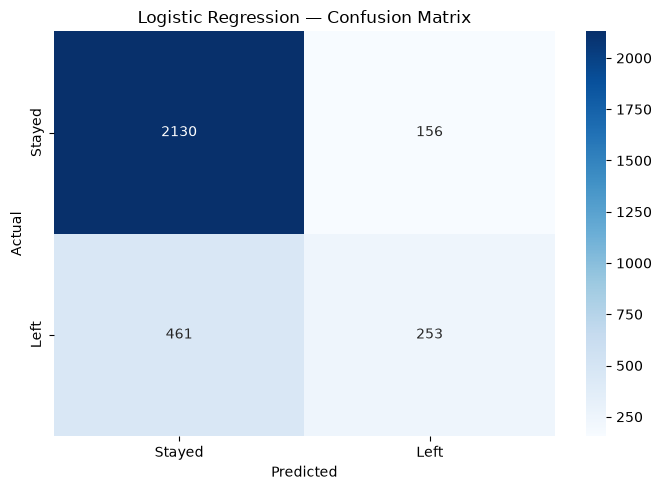

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.show()

Generating Classification Report

In [15]:
from sklearn.metrics import classification_report

logistic_report = classification_report(
    y_test,
    y_pred_logistic,
    target_names=["Stayed", "Left"]
)

print("Logistic Regression Classification Report:")
print(logistic_report)

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Stayed       0.82      0.93      0.87      2286
        Left       0.62      0.35      0.45       714

    accuracy                           0.79      3000
   macro avg       0.72      0.64      0.66      3000
weighted avg       0.77      0.79      0.77      3000



## 5. Logistic Regression — Interpretation

The Logistic Regression model provides an interpretable baseline for employee attrition prediction.

On the held-out test set:

- Accuracy was **79.43%**
- ROC-AUC was **82.80%**
- PR-AUC was **53.42%**
- Precision for employees who left was **61.86%**
- Recall for employees who left was **35.43%**
- F1 score for employees who left was **45.06%**

The model identifies employees who stayed more effectively than employees who left. In particular, the **35.43% recall for the attrition class** means that many employees who actually left were not identified by the model at the default 0.50 classification threshold.

This establishes a useful baseline for the next model.

> **Important:** These results describe predictive performance on the held-out test set. They should not be interpreted as evidence that the model can identify future attrition with the same performance or that predicted risk represents certainty.

## RANDOM FOREST

## 6. Random Forest Model

Logistic Regression provides a linear and interpretable baseline.

The next model is a Random Forest classifier, which can capture non-linear relationships and interactions between employee characteristics.

The Random Forest will use the same training and test data and the same preprocessing approach so that its performance can be compared fairly with Logistic Regression.

In [16]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [17]:
random_forest_pipeline.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


Generating Random Forest Predictions

In [18]:
y_pred_rf = random_forest_pipeline.predict(X_test)

y_prob_rf = random_forest_pipeline.predict_proba(
    X_test
)[:, 1]

print("Random Forest predictions generated successfully.")
print(f"Predicted classes: {len(y_pred_rf):,}")
print(f"Predicted probabilities: {len(y_prob_rf):,}")

Random Forest predictions generated successfully.
Predicted classes: 3,000
Predicted probabilities: 3,000


Evaluating Random Forest Performance

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_precision = precision_score(
    y_test,
    y_pred_rf
)

rf_recall = recall_score(
    y_test,
    y_pred_rf
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf
)

rf_roc_auc = roc_auc_score(
    y_test,
    y_prob_rf
)

rf_pr_auc = average_precision_score(
    y_test,
    y_prob_rf
)

rf_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Score": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc,
        rf_pr_auc
    ]
})

rf_metrics["Score"] = rf_metrics["Score"].round(4)

display(rf_metrics)

,Metric,Score
0,Accuracy,0.9907
1,Precision,0.9957
2,Recall,0.9650
3,F1 Score,0.9801
4,ROC-AUC,0.9912
5,PR-AUC,0.9880


## Comparing the two models

In [20]:
model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Logistic Regression": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1,
        logistic_roc_auc,
        logistic_pr_auc
    ],
    "Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc,
        rf_pr_auc
    ]
})

model_comparison[
    ["Logistic Regression", "Random Forest"]
] = model_comparison[
    ["Logistic Regression", "Random Forest"]
].round(4)

display(model_comparison)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.7943,0.9907
1,Precision,0.6186,0.9957
2,Recall,0.3543,0.9650
3,F1 Score,0.4506,0.9801
4,ROC-AUC,0.8280,0.9912
5,PR-AUC,0.5342,0.9880


Confusion Matrix

In [21]:
rf_cm = confusion_matrix(
    y_test,
    y_pred_rf
)

print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[2283    3]
 [  25  689]]


Visualization

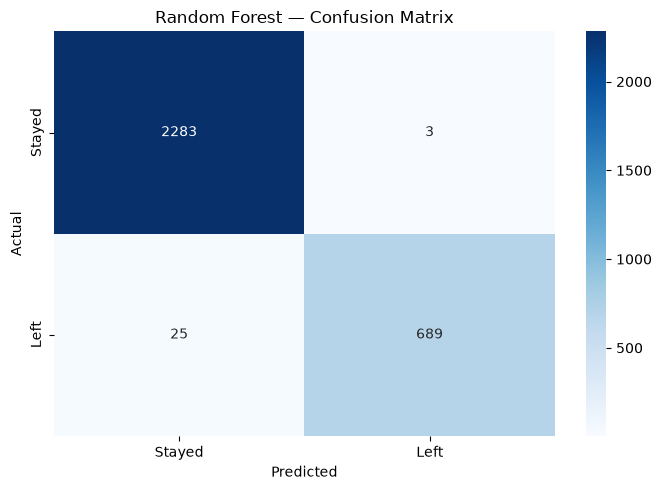

In [22]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.title("Random Forest — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.show()

Classification Report

In [23]:
rf_report = classification_report(
    y_test,
    y_pred_rf,
    target_names=["Stayed", "Left"]
)

print("Random Forest Classification Report:")
print(rf_report)

Random Forest Classification Report:
              precision    recall  f1-score   support

      Stayed       0.99      1.00      0.99      2286
        Left       1.00      0.96      0.98       714

    accuracy                           0.99      3000
   macro avg       0.99      0.98      0.99      3000
weighted avg       0.99      0.99      0.99      3000



Comparing Training Vs Test Performance

In [24]:
y_pred_rf_train = random_forest_pipeline.predict(
    X_train
)

rf_train_accuracy = accuracy_score(
    y_train,
    y_pred_rf_train
)

rf_test_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(f"Random Forest training accuracy: {rf_train_accuracy:.4f}")
print(f"Random Forest test accuracy:     {rf_test_accuracy:.4f}")
print(f"Train-test accuracy gap:         {rf_train_accuracy - rf_test_accuracy:.4f}")

Random Forest training accuracy: 1.0000
Random Forest test accuracy:     0.9907
Train-test accuracy gap:         0.0093


Fold-Cross Validation

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv_scores = cross_val_score(
    random_forest_pipeline,
    X,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Random Forest 5-Fold Cross-Validation ROC-AUC:")

for i, score in enumerate(rf_cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nMean ROC-AUC: {rf_cv_scores.mean():.4f}")
print(f"Std ROC-AUC:  {rf_cv_scores.std():.4f}")

Random Forest 5-Fold Cross-Validation ROC-AUC:
Fold 1: 0.9919
Fold 2: 0.9931
Fold 3: 0.9939
Fold 4: 0.9961
Fold 5: 0.9945

Mean ROC-AUC: 0.9939
Std ROC-AUC:  0.0014


## 7. Random Forest — Validation and Stability

The Random Forest achieved very high predictive performance on the held-out test set:

- Accuracy: **99.07%**
- Precision for attrition: **99.57%**
- Recall for attrition: **96.50%**
- F1 score for attrition: **98.01%**
- ROC-AUC: **99.12%**
- PR-AUC: **98.80%**

The model achieved 100% training accuracy and 99.07% test accuracy, producing a train-test accuracy gap of **0.93 percentage points**.

Five-fold stratified cross-validation produced ROC-AUC scores between **0.9919 and 0.9961**, with a mean of **0.9939** and a standard deviation of **0.0014**.

These results indicate strong and internally consistent predictive performance within this historical dataset.

However, cross-validation does not guarantee equivalent performance on future employees or a different organization. The dataset represents historical employee records from one business context, so external validation would be required before operational deployment.

The unusually high performance also makes feature interpretation and probability analysis important parts of the remaining evaluation.

In [26]:
rf_model = random_forest_pipeline.named_steps["model"]
rf_preprocessor = random_forest_pipeline.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

rf_importance = rf_model.feature_importances_

rf_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
}).sort_values(
    "Importance",
    ascending=False
)

rf_feature_importance["Importance"] = (
    rf_feature_importance["Importance"].round(4)
)

display(rf_feature_importance)

,Feature,Importance
0,num__satisfaction_level,0.3158
4,num__time_spend_company,0.1867
2,num__number_project,0.1830
3,num__average_montly_hours,0.1494
1,num__last_evaluation,0.1235
5,num__Work_accident,0.0098
16,cat__salary_low,0.0080
17,cat__salary_medium,0.0038
15,cat__dept_technical,0.0035
13,cat__dept_sales,0.0034


Satisfaction level was the most important feature in the Random Forest's impurity-based feature importance, followed by tenure, project count, monthly hours, and evaluation score.

Permutation Importance

In [27]:
from sklearn.inspection import permutation_importance

rf_permutation = permutation_importance(
    random_forest_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": rf_permutation.importances_mean,
    "Importance_STD": rf_permutation.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
)

permutation_df["Importance_Mean"] = (
    permutation_df["Importance_Mean"].round(4)
)

permutation_df["Importance_STD"] = (
    permutation_df["Importance_STD"].round(4)
)

display(permutation_df)

,Feature,Importance_Mean,Importance_STD
0,satisfaction_level,0.1062,0.0032
4,time_spend_company,0.0622,0.0024
2,number_project,0.0460,0.0018
3,average_montly_hours,0.0214,0.0017
1,last_evaluation,0.0137,0.0016
7,dept,0.0007,0.0007
8,salary,0.0004,0.0007
5,Work_accident,0.0002,0.0003
6,promotion_last_5years,0.0000,0.0001


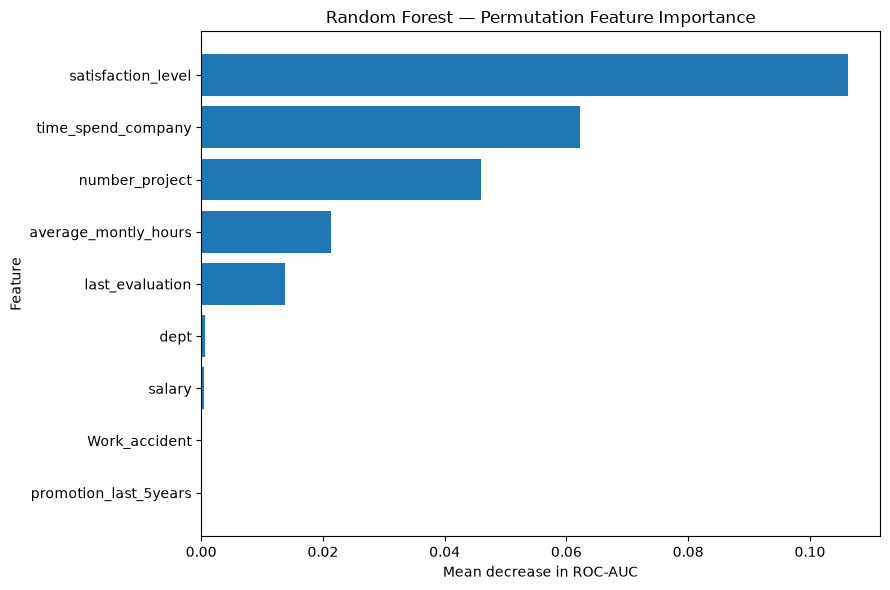

Saved to: c:\Users\hp\Documents\GitHub\employee-attrition-analysis\visuals\rf_permutation_feature_importance.png


In [28]:
plt.figure(figsize=(9, 6))

plot_df = permutation_df.sort_values(
    "Importance_Mean",
    ascending=True
)

plt.barh(
    plot_df["Feature"],
    plot_df["Importance_Mean"]
)

plt.xlabel("Mean decrease in ROC-AUC")
plt.ylabel("Feature")
plt.title("Random Forest — Permutation Feature Importance")

plt.tight_layout()

output_path = (
    PROJECT_ROOT
    / "visuals"
    / "rf_permutation_feature_importance.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

Extracting Logistic Regression coefficients

In [29]:
logistic_model = logistic_pipeline.named_steps["model"]
logistic_preprocessor = logistic_pipeline.named_steps["preprocessor"]

logistic_feature_names = (
    logistic_preprocessor.get_feature_names_out()
)

logistic_coefficients = logistic_model.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": logistic_feature_names,
    "Coefficient": logistic_coefficients
})

coefficient_df["Abs_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

coefficient_df["Coefficient"] = (
    coefficient_df["Coefficient"].round(4)
)

display(
    coefficient_df[
        ["Feature", "Coefficient"]
    ]
)

,Feature,Coefficient
16,cat__salary_low,1.8011
17,cat__salary_medium,1.2677
0,num__satisfaction_level,-1.0221
5,num__Work_accident,-0.5350
9,cat__dept_hr,0.4983
7,cat__dept_RandD,-0.4344
2,num__number_project,-0.3949
4,num__time_spend_company,0.3917
10,cat__dept_management,-0.2662
15,cat__dept_technical,0.2639


## 9. Logistic Regression — Coefficient Interpretation

The Logistic Regression coefficients provide an interpretable view of the direction of modeled associations.

The largest absolute coefficients include:

- `salary_low`: **+1.8011**
- `salary_medium`: **+1.2677**
- `satisfaction_level`: **−1.0221**
- `Work_accident`: **−0.5350**
- `dept_hr`: **+0.4983**
- `dept_RandD`: **−0.4344**

For numeric variables, the coefficients reflect the effect of a one-standard-deviation increase because the numeric features were standardized before modeling.

For categorical variables, coefficients represent differences relative to the reference category created during one-hot encoding.

The negative coefficient for satisfaction indicates that higher satisfaction is associated with lower modeled attrition odds, while positive coefficients indicate higher modeled attrition odds relative to the relevant reference or standardized baseline.

These coefficients describe associations learned by the predictive model. They should not be interpreted as causal effects.

Visualization

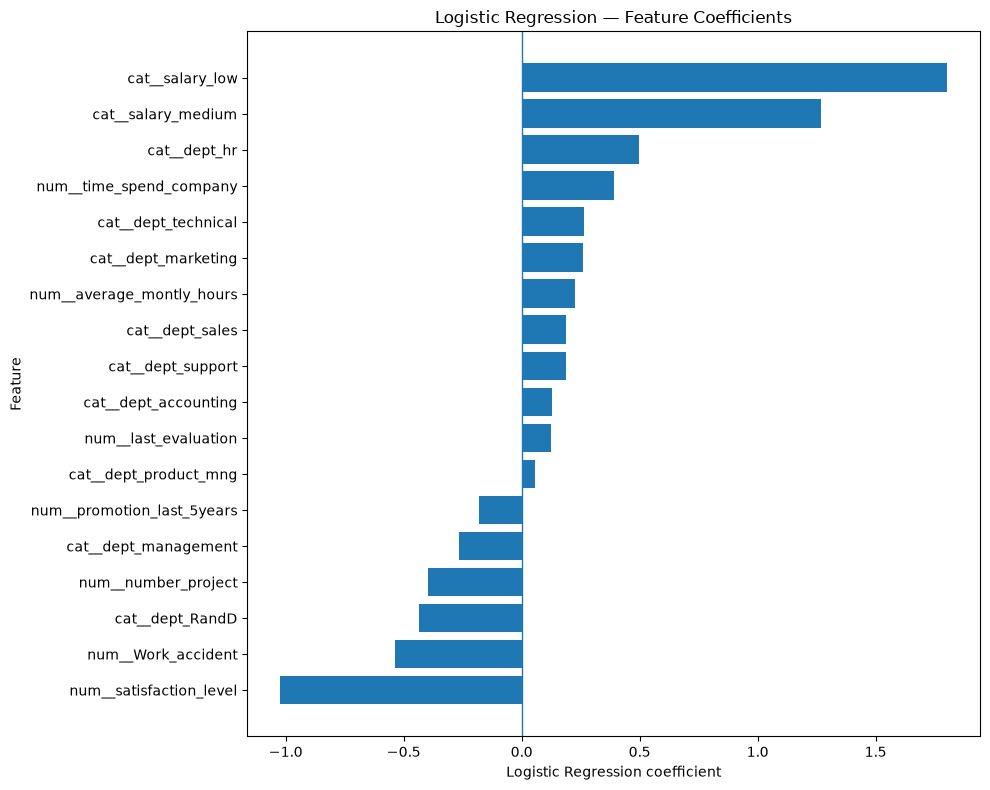

Saved to: c:\Users\hp\Documents\GitHub\employee-attrition-analysis\visuals\logistic_regression_coefficients.png


In [30]:
plt.figure(figsize=(10, 8))

plot_coef = coefficient_df.sort_values(
    "Coefficient"
)

plt.barh(
    plot_coef["Feature"],
    plot_coef["Coefficient"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Logistic Regression coefficient")
plt.ylabel("Feature")
plt.title("Logistic Regression — Feature Coefficients")

plt.tight_layout()

output_path = (
    PROJECT_ROOT
    / "visuals"
    / "logistic_regression_coefficients.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

Examining Random Forest predicted probabilities

In [31]:
probability_summary = pd.Series(
    y_prob_rf
).describe()

display(
    probability_summary.to_frame(
        name="Predicted_Probability"
    )
)

,Predicted_Probability
count,3000.000000
mean,0.243573
std,0.404830
min,0.000000
25%,0.000000
50%,0.013333
75%,0.166667
max,1.000000


## 10. Predicted Attrition Risk Bands

To make the model output easier to interpret from a business perspective, predicted probabilities are grouped into risk bands.

The bands are:

- **0–10%** — Very low predicted risk
- **10–25%** — Low predicted risk
- **25–50%** — Moderate predicted risk
- **50–75%** — Elevated predicted risk
- **75–90%** — High predicted risk
- **90–100%** — Very high predicted risk

These categories describe model output within the held-out test population. They do not represent probabilities of certainty and should not be interpreted as causal or guaranteed outcomes.

In [32]:
risk_bins = pd.cut(
    y_prob_rf,
    bins=[0, 0.10, 0.25, 0.50, 0.75, 0.90, 1.00],
    labels=[
        "0–10%",
        "10–25%",
        "25–50%",
        "50–75%",
        "75–90%",
        "90–100%"
    ],
    include_lowest=True
)

risk_band_summary = (
    pd.Series(risk_bins)
    .value_counts()
    .sort_index()
    .rename("Employee_Count")
    .to_frame()
)

risk_band_summary["Percentage"] = (
    risk_band_summary["Employee_Count"]
    / len(y_prob_rf)
    * 100
)

risk_band_summary["Percentage"] = (
    risk_band_summary["Percentage"].round(2)
)

display(risk_band_summary)

,Employee_Count,Percentage
0–10%,2161,72.03
10–25%,125,4.17
25–50%,22,0.73
50–75%,14,0.47
75–90%,37,1.23
90–100%,641,21.37


## 11. Observed Attrition Within Predicted Risk Bands

Predicted risk bands are compared with the actual attrition outcomes in the held-out test set.

This provides a business-oriented validation of whether employees assigned higher predicted risk actually experienced higher observed attrition rates.

The analysis remains descriptive: observed attrition within a risk band does not mean the model caused the outcome or that the predicted probability represents certainty.

In [33]:
risk_band_validation = pd.DataFrame({
    "Predicted_Risk_Band": risk_bins,
    "Actual_Attrition": y_test.to_numpy()
})

risk_band_validation_summary = (
    risk_band_validation
    .groupby("Predicted_Risk_Band", observed=False)
    .agg(
        Employee_Count=("Actual_Attrition", "size"),
        Employees_Left=("Actual_Attrition", "sum"),
        Observed_Attrition_Rate=("Actual_Attrition", "mean")
    )
)

risk_band_validation_summary["Observed_Attrition_Rate"] = (
    risk_band_validation_summary["Observed_Attrition_Rate"] * 100
).round(2)

display(risk_band_validation_summary)

,Employee_Count,Employees_Left,Observed_Attrition_Rate
Predicted_Risk_Band,,,
0–10%,2161,17,0.79
10–25%,125,4,3.20
25–50%,22,4,18.18
50–75%,14,14,100.00
75–90%,37,36,97.30
90–100%,641,639,99.69


## 12. Predicted Risk vs Observed Attrition

The relationship between predicted risk and observed attrition is visualized below.

A useful risk model should generally produce higher observed attrition rates among groups assigned higher predicted risk.

The chart should be interpreted alongside the number of employees in each band, particularly for the smaller intermediate-risk groups.

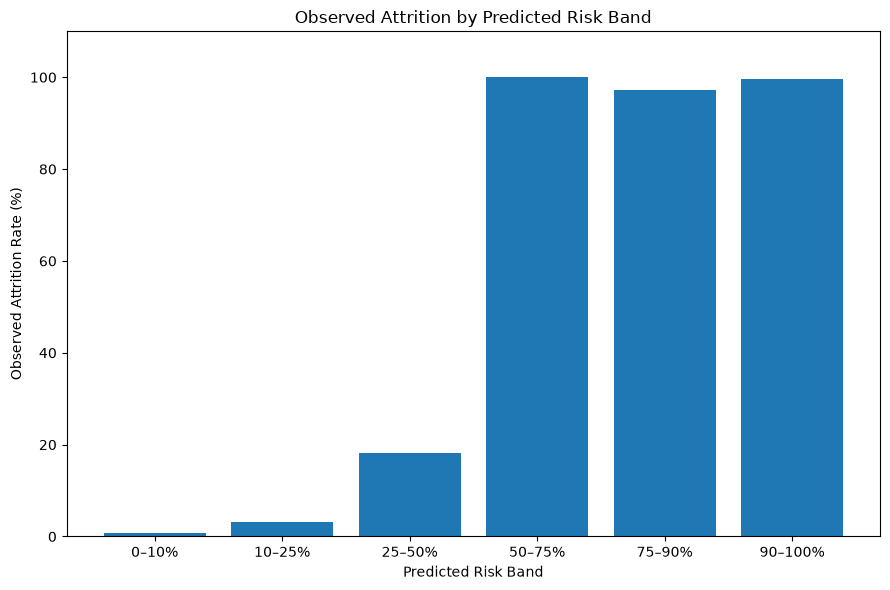

Saved to: c:\Users\hp\Documents\GitHub\employee-attrition-analysis\visuals\observed_attrition_by_risk_band.png


In [34]:
plt.figure(figsize=(9, 6))

plt.bar(
    risk_band_validation_summary.index.astype(str),
    risk_band_validation_summary["Observed_Attrition_Rate"]
)

plt.xlabel("Predicted Risk Band")
plt.ylabel("Observed Attrition Rate (%)")
plt.title("Observed Attrition by Predicted Risk Band")

plt.ylim(0, 110)

plt.tight_layout()

output_path = PROJECT_ROOT / "visuals" / "observed_attrition_by_risk_band.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")


## 13. Probability Calibration

A model can have strong discrimination while its predicted probabilities are not perfectly calibrated.

Calibration asks whether predicted probabilities correspond reasonably closely to observed outcomes.

For example, among employees assigned a predicted attrition probability of approximately 80%, a well-calibrated model would ideally observe an attrition rate close to 80% within a sufficiently large group.

This analysis evaluates the Random Forest's predicted probabilities against observed attrition in the held-out test set.

> **Important:** Calibration results are descriptive for this historical test population. They do not establish that the same probabilities would apply to future employees or another organization.

In [35]:
from sklearn.calibration import calibration_curve

calibration_fraction, calibration_mean = calibration_curve(
    y_test,
    y_prob_rf,
    n_bins=10,
    strategy="quantile"
)

calibration_df = pd.DataFrame({
    "Mean_Predicted_Probability": calibration_mean,
    "Observed_Attrition_Rate": calibration_fraction
})

calibration_df = calibration_df.round(4)

display(calibration_df)

,Mean_Predicted_Probability,Observed_Attrition_Rate
0,0.0000,0.0037
1,0.0033,0.0119
2,0.0067,0.0000
3,0.0114,0.0046
4,0.0211,0.0000
5,0.0455,0.0201
6,0.3729,0.3412
7,0.9944,0.9983


## 14. Calibration Curve

The calibration curve compares mean predicted attrition probability with the observed attrition rate across probability groups.

A perfectly calibrated model would follow the diagonal reference line.

The curve is used here to assess whether the Random Forest's probability outputs are reasonably aligned with observed outcomes in the held-out test population.

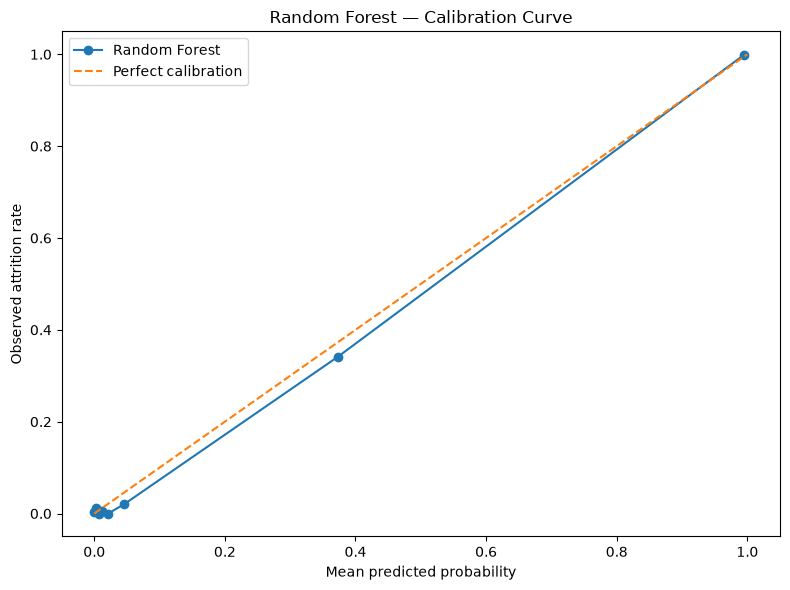

In [36]:
plt.figure(figsize=(8, 6))

plt.plot(
    calibration_mean,
    calibration_fraction,
    marker="o",
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed attrition rate")
plt.title("Random Forest — Calibration Curve")

plt.legend()
plt.tight_layout()

plt.show()

## 15. Classification Threshold Analysis

The default classification threshold of 0.50 is not necessarily the only useful operating point.

Lowering the threshold generally identifies more employees as potentially at risk, increasing recall while potentially reducing precision.

Raising the threshold generally produces a smaller group of flagged employees, but may miss more employees who eventually leave.

The analysis below compares several thresholds using precision, recall, and F1 score on the held-out test set.

> **Important:** The appropriate threshold depends on the business cost of missed attrition versus unnecessary intervention. The analysis does not prescribe a single threshold.

In [37]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(
    0.10,
    0.91,
    0.10
)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_rf >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            y_pred_threshold
        ),
        "Recall": recall_score(
            y_test,
            y_pred_threshold
        ),
        "F1 Score": f1_score(
            y_test,
            y_pred_threshold
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df[
    ["Precision", "Recall", "F1 Score"]
] = threshold_df[
    ["Precision", "Recall", "F1 Score"]
].round(4)

display(threshold_df)

,Threshold,Precision,Recall,F1 Score
0,0.1,0.8268,0.9762,0.8953
1,0.2,0.9506,0.9706,0.9605
2,0.3,0.9816,0.9692,0.9753
3,0.4,0.9900,0.9664,0.9780
4,0.5,0.9957,0.9650,0.9801
5,0.6,0.9956,0.9608,0.9779
6,0.7,0.9956,0.9454,0.9698
7,0.8,0.9956,0.9440,0.9691
8,0.9,0.9969,0.8964,0.9440


## 16. Precision–Recall Trade-off by Classification Threshold

The threshold analysis demonstrates the trade-off between precision and recall.

Lower thresholds classify more employees as potentially at risk, which increases the number of attrition cases captured but also increases false positives.

Higher thresholds produce a more selective group of predicted attrition cases, increasing precision while reducing recall.

The appropriate operating threshold should therefore be determined using the organization's intervention capacity and the relative cost of missed versus unnecessary retention interventions.

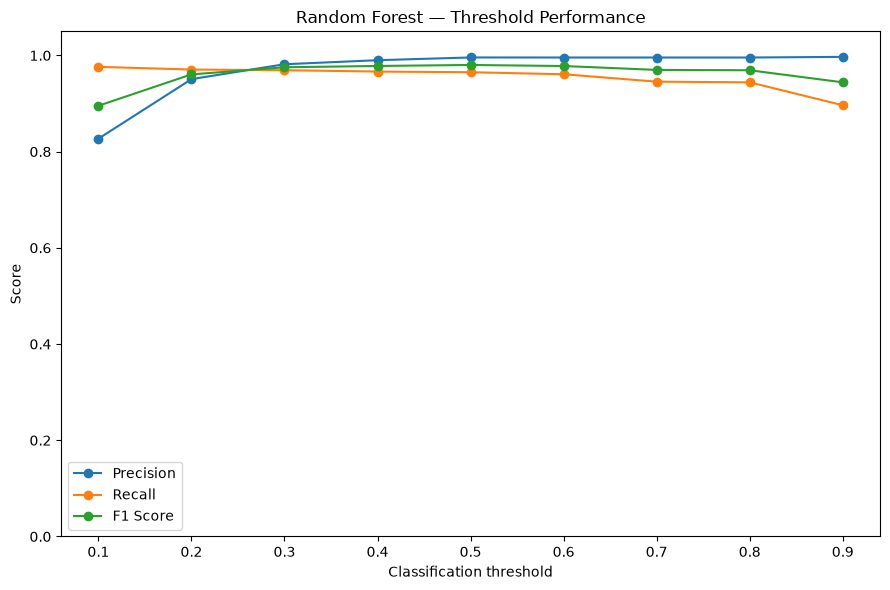

In [38]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification threshold")
plt.ylabel("Score")
plt.title("Random Forest — Threshold Performance")

plt.ylim(0, 1.05)

plt.legend()
plt.tight_layout()

plt.show()

## 17. Employee-Level Predicted Risk Output

The model predictions are combined with employee characteristics to create an employee-level risk dataset.

This output is intended to demonstrate how the predictive model could support downstream HR analysis.

The initial risk classification uses a 0.50 probability threshold:

- **Higher predicted risk**: predicted probability ≥ 50%
- **Lower predicted risk**: predicted probability < 50%

The classification is a model output, not a statement that an employee will leave.

In [39]:
model_output = X_test.copy()

model_output["Emp ID"] = df_model.loc[
    X_test.index,
    "Emp ID"
]

model_output["Actual_Attrition"] = y_test

model_output["Predicted_Attrition"] = y_pred_rf

model_output["Predicted_Probability"] = y_prob_rf

model_output["Risk_Class"] = np.where(
    model_output["Predicted_Probability"] >= 0.50,
    "Higher predicted risk",
    "Lower predicted risk"
)

model_output = model_output[
    [
        "Emp ID",
        "satisfaction_level",
        "last_evaluation",
        "number_project",
        "average_montly_hours",
        "time_spend_company",
        "Work_accident",
        "promotion_last_5years",
        "dept",
        "salary",
        "Actual_Attrition",
        "Predicted_Attrition",
        "Predicted_Probability",
        "Risk_Class"
    ]
].sort_values(
    "Predicted_Probability",
    ascending=False
)

display(
    model_output.head(20)
)

,Emp ID,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,dept,salary,Actual_Attrition,Predicted_Attrition,Predicted_Probability,Risk_Class
330,331,0.38,0.57,2,140,3,0,0,sales,low,1,1,1.0,Higher predicted risk
14232,14233,0.38,0.55,2,147,3,0,0,sales,low,1,1,1.0,Higher predicted risk
12395,12396,0.45,0.46,2,128,3,0,0,sales,low,1,1,1.0,Higher predicted risk
12115,12116,0.37,0.48,2,137,3,0,0,technical,medium,1,1,1.0,Higher predicted risk
14375,14376,0.90,0.99,5,260,5,0,0,sales,low,1,1,1.0,Higher predicted risk
97,98,0.10,0.84,6,279,4,0,0,sales,low,1,1,1.0,Higher predicted risk
1793,1794,0.43,0.51,2,143,3,0,0,technical,medium,1,1,1.0,Higher predicted risk
1443,1444,0.11,0.88,7,305,4,0,0,product_mng,low,1,1,1.0,Higher predicted risk
508,509,0.38,0.55,2,158,3,0,0,support,low,1,1,1.0,Higher predicted risk
12372,12373,0.39,0.48,2,141,3,0,0,product_mng,medium,1,1,1.0,Higher predicted risk


## 18. Risk Group Profile

The employee-level predictions are summarized into higher- and lower-predicted-risk groups.

This comparison helps describe how the model separates employees based on their predicted attrition risk and allows the observed attrition rate within each group to be examined.

The risk groups are defined using the 0.50 classification threshold used for the initial model evaluation.

> **Important:** Differences between groups describe patterns in the held-out test population. They should not be interpreted as causal effects.

In [40]:
risk_profile = (
    model_output
    .groupby("Risk_Class")
    .agg(
        Employee_Count=("Emp ID", "count"),
        Avg_Satisfaction=("satisfaction_level", "mean"),
        Avg_Evaluation=("last_evaluation", "mean"),
        Avg_Projects=("number_project", "mean"),
        Avg_Monthly_Hours=("average_montly_hours", "mean"),
        Avg_Tenure=("time_spend_company", "mean"),
        Observed_Attrition_Rate=("Actual_Attrition", "mean")
    )
)

risk_profile["Employee_Share"] = (
    risk_profile["Employee_Count"]
    / len(model_output)
    * 100
)

risk_profile["Observed_Attrition_Rate"] = (
    risk_profile["Observed_Attrition_Rate"]
    * 100
)

risk_profile = risk_profile.round(2)

display(risk_profile)

,Employee_Count,Avg_Satisfaction,Avg_Evaluation,Avg_Projects,Avg_Monthly_Hours,Avg_Tenure,Observed_Attrition_Rate,Employee_Share
Risk_Class,,,,,,,,
Higher predicted risk,692,0.43,0.72,3.87,208.26,3.88,99.57,23.07
Lower predicted risk,2308,0.67,0.72,3.80,199.27,3.37,1.08,76.93


## 19. Observed Attrition Lift

Observed attrition lift compares the attrition rate within the higher predicted-risk group with the overall attrition rate in the held-out test population.

A lift greater than 1 indicates that the higher-risk group had a higher observed attrition rate than the overall test population.

This is an observed descriptive measure, not a causal effect and not a guarantee of future performance.

In [41]:
overall_test_attrition_rate = (
    y_test.mean()
)

higher_risk_attrition_rate = (
    model_output.loc[
        model_output["Risk_Class"] == "Higher predicted risk",
        "Actual_Attrition"
    ].mean()
)

lower_risk_attrition_rate = (
    model_output.loc[
        model_output["Risk_Class"] == "Lower predicted risk",
        "Actual_Attrition"
    ].mean()
)

higher_risk_lift = (
    higher_risk_attrition_rate
    / overall_test_attrition_rate
)

lower_risk_lift = (
    lower_risk_attrition_rate
    / overall_test_attrition_rate
)

lift_summary = pd.DataFrame({
    "Group": [
        "Overall test population",
        "Higher predicted risk",
        "Lower predicted risk"
    ],
    "Observed_Attrition_Rate": [
        overall_test_attrition_rate * 100,
        higher_risk_attrition_rate * 100,
        lower_risk_attrition_rate * 100
    ],
    "Lift_vs_Overall": [
        1,
        higher_risk_lift,
        lower_risk_lift
    ]
})

lift_summary[
    ["Observed_Attrition_Rate", "Lift_vs_Overall"]
] = lift_summary[
    ["Observed_Attrition_Rate", "Lift_vs_Overall"]
].round(2)

display(lift_summary)

,Group,Observed_Attrition_Rate,Lift_vs_Overall
0,Overall test population,23.80,1.00
1,Higher predicted risk,99.57,4.18
2,Lower predicted risk,1.08,0.05


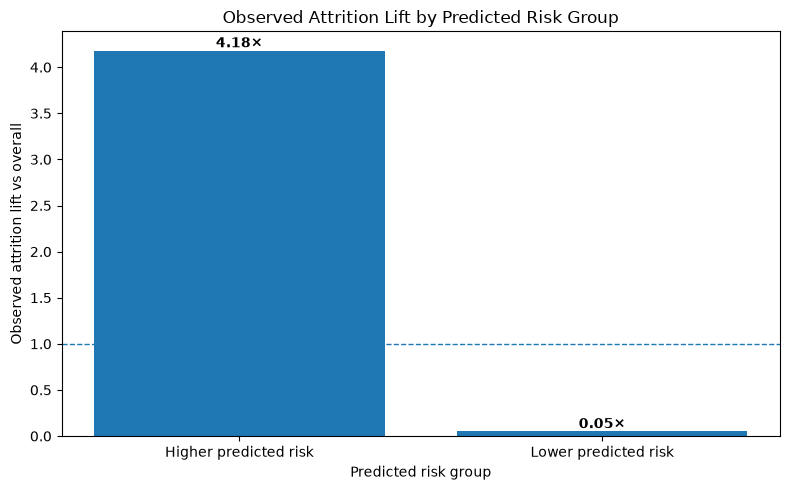

Saved to: c:\Users\hp\Documents\GitHub\employee-attrition-analysis\visuals\observed_attrition_lift_by_risk_group.png


In [44]:
lift_plot_df = lift_summary[
    lift_summary["Group"] != "Overall test population"
].copy()

lift_plot_df["Risk_Group_Label"] = lift_plot_df["Group"].map({
    "Higher predicted risk": "Higher predicted risk",
    "Lower predicted risk": "Lower predicted risk"
})

plt.figure(figsize=(8, 5))

bars = plt.bar(
    lift_plot_df["Risk_Group_Label"],
    lift_plot_df["Lift_vs_Overall"]
)

plt.axhline(
    1,
    linestyle="--",
    linewidth=1
)

# Add lift values above the bars
for bar, value in zip(
    bars,
    lift_plot_df["Lift_vs_Overall"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}×",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.ylabel("Observed attrition lift vs overall")
plt.xlabel("Predicted risk group")
plt.title("Observed Attrition Lift by Predicted Risk Group")

plt.tight_layout()

output_path = (
    PROJECT_ROOT
    / "visuals"
    / "observed_attrition_lift_by_risk_group.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

## 20. Predictive Modeling — Key Findings

The predictive modeling workflow produced several important findings.

### 1. Logistic Regression established an interpretable baseline

The Logistic Regression model achieved:

- Accuracy: **79.43%**
- ROC-AUC: **82.80%**
- PR-AUC: **53.42%**
- Attrition precision: **61.86%**
- Attrition recall: **35.43%**
- Attrition F1 score: **45.06%**

The model demonstrated useful discrimination but missed a substantial proportion of employees who actually left at the default 0.50 threshold.

### 2. Random Forest substantially improved predictive separation

The Random Forest achieved:

- Accuracy: **99.07%**
- ROC-AUC: **99.12%**
- PR-AUC: **98.80%**
- Attrition precision: **99.57%**
- Attrition recall: **96.50%**
- Attrition F1 score: **98.01%**

Five-fold cross-validation produced a mean ROC-AUC of **99.39%**, with a standard deviation of **0.14 percentage points**.

These results indicate very strong and internally consistent predictive performance within this historical dataset.

### 3. The strongest predictive signals were concentrated in five variables

Both Random Forest impurity importance and permutation importance identified the same leading variables:

1. `satisfaction_level`
2. `time_spend_company`
3. `number_project`
4. `average_montly_hours`
5. `last_evaluation`

The agreement between the two feature-importance approaches provides additional support for their importance to this model.

These importance measures describe predictive contribution or association within the model. They do not establish causal effects.

### 4. The model separated the held-out test population into distinctly different risk groups

Using the 0.50 classification threshold:

- **692 employees (23.07%)** were classified as higher predicted risk.
- **2,308 employees (76.93%)** were classified as lower predicted risk.

Observed attrition was:

- **99.57%** in the higher predicted-risk group
- **1.08%** in the lower predicted-risk group
- **23.80%** across the overall test population

The higher predicted-risk group therefore showed an observed attrition lift of **4.18× relative to the overall test population**.

This result is descriptive of the held-out test population and should not be interpreted as a guarantee of future employee outcomes.

### 5. Classification threshold affects the operating trade-off

The Random Forest achieved a 96.50% attrition recall and 99.57% precision at the default 0.50 threshold.

Lowering the threshold increased recall while accepting more false positives. For example:

- At **0.10**, recall increased to **97.62%** while precision decreased to **82.68%**.
- At **0.20**, recall was **97.06%** and precision was **95.06%**.
- At **0.50**, recall was **96.50%** and precision was **99.57%**.
- At **0.90**, precision increased to **99.69%**, while recall decreased to **89.64%**.

The appropriate operating threshold therefore depends on the relative cost of missed attrition cases, unnecessary interventions, and the organization's available intervention capacity.

### 6. Probability outputs require careful interpretation

The Random Forest demonstrated strong separation between lower- and higher-risk employees.

However, its predicted probabilities should not automatically be interpreted as perfectly calibrated individual-level probabilities. The calibration analysis showed particularly strong alignment at the high-risk end, while lower-risk probability groups showed some variation.

External validation and, if necessary, probability calibration would be appropriate before using these scores operationally.

### Overall conclusion

The rebuilt analysis demonstrates that historical employee characteristics can be used to identify employees with substantially different levels of predicted attrition risk within this dataset.

The strongest predictive signals were associated with satisfaction, tenure, project assignment, working hours, and evaluation.

The Random Forest substantially outperformed the Logistic Regression baseline on the held-out test set and showed strong internal cross-validation performance.

However, the unusually high predictive performance should be interpreted within the context of the dataset. The data represents historical employee records from a single organizational context, and external validation would be required before assuming similar performance on future employees or another organization.

The model should therefore be viewed as an analytical risk-screening framework rather than a definitive predictor of individual employee behavior.

## 21. Limitations and Analytical Considerations

Several limitations should be considered when interpreting the results.

### 1. Historical single-organization dataset

The dataset represents historical employee records from one organizational context.

Model performance may therefore differ when applied to:

- Future employees
- Different time periods
- Different departments or business units
- Another organization

External validation would be required before operational deployment.

### 2. Observational data does not establish causation

The analysis identifies statistical associations and predictive patterns.

For example, the relationship between satisfaction, working hours, tenure, and attrition does not demonstrate that changing any one of these variables would necessarily change an employee's probability of leaving.

The results should therefore support further investigation rather than be interpreted as causal evidence.

### 3. Potentially limited feature set

The dataset contains useful employee and work-related characteristics, but it does not include many factors that could potentially influence employee retention, such as:

- Compensation amount
- Manager characteristics
- Employee engagement
- Commute time
- Absence history
- Training participation
- Job-level information
- Internal mobility
- Employee survey responses
- External labour-market conditions

The absence of these variables limits the information available to the model.

### 4. Temporal validation was not possible

The available dataset does not provide a suitable time-based structure for a true historical-to-future validation design.

The analysis therefore uses a stratified train/test split and cross-validation.

A production system should ideally be evaluated using a time-based validation strategy where models are trained on earlier employee records and evaluated on later records.

### 5. Very high Random Forest performance requires caution

The Random Forest achieved exceptionally high performance on this dataset.

Although the model was evaluated using held-out data and five-fold cross-validation, very high performance should not automatically be assumed to generalize outside the dataset.

Further investigation would be appropriate before operational use, including:

- External validation
- Temporal validation
- Monitoring for data drift
- Probability calibration
- Review of feature definitions
- Evaluation on genuinely future observations

### 6. Risk scores should support human review

A predicted risk score should not be treated as a definitive statement that an employee will leave.

In a real HR setting, model outputs would be better used to identify groups or cases for further review, while decisions remain subject to appropriate human judgment, organizational policies, and relevant employment requirements.

### Overall limitation

The model demonstrates strong predictive performance within the available historical dataset, but the analysis should be interpreted as a portfolio demonstration of predictive employee analytics rather than a production-ready employee decision system.

## 22. Methodology Improvements — 2020 vs 2026

This project was rebuilt from an earlier employee attrition analysis and provides an opportunity to improve the original methodology.

| Area | Original Analysis | Rebuilt Analysis |
|---|---|---|
| Feature selection | Employee ID was included among model inputs | Employee ID explicitly excluded |
| Categorical variables | Department and salary were analysed but excluded from the original model | Department and salary incorporated through one-hot encoding |
| Target handling | Attrition represented as a categorical variable | Explicit binary target created |
| Preprocessing | Manual feature preparation | Scikit-learn preprocessing pipeline |
| Baseline model | Random Forest focused primarily on accuracy | Logistic Regression added as an interpretable baseline |
| Model comparison | Limited | Logistic Regression vs Random Forest |
| Evaluation | Accuracy, confusion matrix and classification report | Accuracy, precision, recall, F1, ROC-AUC and PR-AUC |
| Validation | Single train/test split | Stratified train/test split plus five-fold cross-validation |
| Feature interpretation | Basic feature importance | Impurity importance, permutation importance and Logistic Regression coefficients |
| Probability analysis | Not included | Predicted probability distribution and risk bands |
| Risk segmentation | Not included | Employee-level predicted-risk groups |
| Calibration | Not included | Calibration curve analysis |
| Threshold analysis | Not included | Precision–recall trade-off across thresholds |
| Statistical analysis | Descriptive analysis | Chi-square, Cramér's V and Mann–Whitney U |
| Interpretation | Some causal language | Association and predictive language |
| Limitations | Limited discussion | Explicit generalisation, validation and deployment limitations |

### Key methodological lesson

The original analysis produced a very high Random Forest accuracy, but including Employee ID as a model feature created a methodological weakness because an identifier does not represent an employee characteristic.

The rebuilt analysis removes Employee ID from the feature matrix and evaluates the model using a broader set of appropriate predictive features and multiple validation metrics.

The project therefore demonstrates not only model building, but also the importance of questioning unexpectedly strong results and validating whether the modeling approach is methodologically appropriate.

## 23. Business Implications and Potential Actions

The analysis can be translated into several potential areas for HR and management review.

These are **data-informed intervention hypotheses**, not causal conclusions. The historical analysis identifies groups and characteristics associated with elevated predicted risk, but it does not demonstrate that a specific intervention will prevent attrition.

### 1. Prioritise targeted retention reviews

The predicted-risk output could be used to prioritise employees or employee groups for voluntary retention conversations and further review.

A risk score should be treated as a screening signal rather than a definitive assessment of an individual employee.

### 2. Investigate workload patterns

Working hours and project assignment were among the variables that contributed substantially to model predictions.

HR and management could investigate whether employees with unusually high workloads, unusual project combinations, or sustained workload pressure are experiencing different retention outcomes.

This should be investigated alongside operational context rather than assuming workload itself is the cause of attrition.

### 3. Monitor employee satisfaction

Satisfaction was the strongest predictor according to both Random Forest feature-importance approaches.

Regular engagement or satisfaction monitoring could therefore provide an additional source of information for retention analysis.

Any employee survey data should be handled appropriately and analysed at a suitable level of aggregation.

### 4. Examine tenure-related patterns

Tenure showed a strong relationship with attrition in the historical data and was one of the strongest predictive variables.

The organisation could examine retention patterns at different stages of the employee lifecycle and investigate whether particular tenure groups require additional onboarding, career-development, or engagement support.

### 5. Review project allocation

The number of projects was among the leading predictive variables.

Management could examine whether certain project workloads or combinations are associated with higher employee turnover and whether project allocation practices warrant further investigation.

The analysis does not establish that a particular number of projects causes attrition.

### 6. Use model thresholds according to intervention capacity

The threshold analysis demonstrates that different classification thresholds produce different precision and recall trade-offs.

If an HR team has limited capacity for retention interventions, a more selective threshold may be appropriate.

If the cost of missing potentially at-risk employees is considered more important, a lower threshold could be investigated.

The appropriate threshold should therefore be selected using documented business costs, intervention capacity, and validation on relevant future data.

### 7. Establish monitoring before operational deployment

Before using the model operationally, the organisation should establish a monitoring framework covering:

- Prediction performance over time
- Calibration
- Data drift
- Feature availability
- False positives and false negatives
- Model performance across relevant employee groups
- Changes in organisational processes or policies

The model should be periodically revalidated as employee behaviour and organisational conditions change.

### Business takeaway

The value of the analysis is not simply the prediction score.

The broader opportunity is to use employee data to identify patterns, prioritise questions for HR teams, and support evidence-based retention analysis while keeping human review and appropriate organisational safeguards in the decision process.

## 24. Final Conclusion

This project rebuilt an earlier employee attrition analysis using a more rigorous analytical and machine-learning workflow.

The analysis combined:

- Exploratory data analysis
- Statistical association testing
- Effect-size analysis
- Logistic Regression
- Random Forest
- Multiple classification metrics
- Cross-validation
- Feature importance analysis
- Permutation importance
- Predicted-risk segmentation
- Calibration analysis
- Classification-threshold analysis
- Business interpretation

The historical dataset contained an overall attrition rate of **23.81%**.

The Random Forest achieved **99.12% ROC-AUC** and **98.80% PR-AUC** on the held-out test set, with a five-fold cross-validation mean ROC-AUC of **99.39%**.

The strongest predictive variables were satisfaction, tenure, project count, monthly working hours, and evaluation score.

The model also separated the held-out test population into substantially different observed attrition groups, with the higher predicted-risk group showing a **4.18× observed attrition lift relative to the overall test population**.

Despite these strong results, the model should not be interpreted as a guarantee of future employee behavior. The dataset represents historical observations from a specific organizational context, and external and temporal validation would be required before operational deployment.

The primary outcome of this project is therefore a structured analytical framework for understanding and predicting employee attrition risk—not a definitive automated decision system.

The rebuild also demonstrates a broader methodological lesson: strong model performance must be accompanied by appropriate feature selection, validation, interpretation, and critical examination of how the model reaches its results.